In [305]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-notebook")
import numpy as np
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

SEED = 42

In [306]:
print(plt.style.available)

['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


In [307]:
# kagglehub.login()

In [308]:
# # Download latest version
# path = kagglehub.competition_download('titanic',output_dir = r'C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\Titanic\df')

# print("Path to competition files:", path)

## Цель - построить модель прогноза выживет ли пассажир или нет

In [309]:
df = pd.read_csv("./data/train.csv")

## df Dictionary

| Variable | Definition | Key |
|---|---|---|
| `survival` | Survival | 0 = No, 1 = Yes |
| `pclass` | Ticket class | 1 = 1st, 2 = 2nd, 3 = 3rd |
| `sex` | Sex | — |
| `Age` | Age in years | — |
| `sibsp` | Number of siblings / spouses aboard the Titanic | — |
| `parch` | Number of parents / children aboard the Titanic | — |
| `ticket` | Ticket number | — |
| `fare` | Passenger fare | — |
| `cabin` | Cabin number | — |
| `embarked` | Port of Embarkation | C = Cherbourg, Q = Queenstown, S = Southampton |

In [310]:
len(df)

891

In [311]:
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [312]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


По данной таблице можно сказать что выжило 38% пассажиров, средний возраст 30 лет, в среднем за билет запалатилии 32 фунта

In [313]:
df.isnull().sum()  # смотрим пропуски по каждой из фичей

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

По данным возраста, каюты и порта отправления есть пропуски, стоит их заполинить в зависимости от типа фичи

## Исследование каждой из фичей

    Целевая переменная

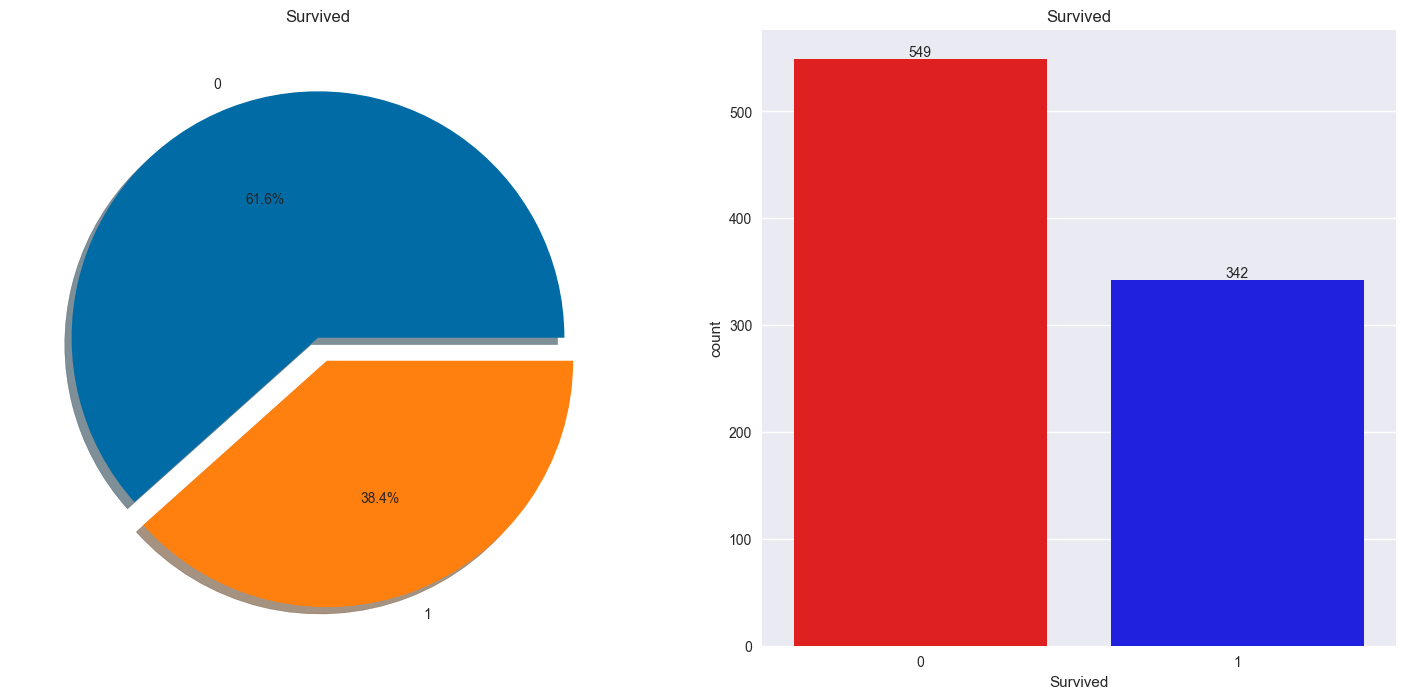

In [314]:
f, ax = plt.subplots(1, 2, figsize=(18, 8))
df["Survived"].value_counts().plot.pie(
    explode=[0, 0.1], autopct="%1.1f%%", ax=ax[0], shadow=True
)
ax[0].set_title("Survived")
ax[0].set_ylabel("")
sns.countplot(x=df["Survived"], ax=ax[1], palette=["r", "b"])
ax[1].set_title("Survived")
for container in ax[1].containers:
    ax[1].bar_label(container)
plt.show()

Как мы видим выжила только одна треть (38%) от всех пассажиров, давайте рассмотрим остальные фичи и посмотрим как они влияют на выживание

### Типы признаков
### Категориальные признаки (Categorical Features)

Категориальная переменная — это переменная, которая имеет **две или более категории**, и каждое значение этого признака может быть отнесено к одной из них.

Например, `Sex` (пол) — это категориальная переменная с двумя категориями:

- `male` — мужчина
- `female` — женщина

При этом мы **не можем упорядочить** эти категории или сказать, что одна из них «больше» или «меньше» другой. Такие переменные также называются **номинальными переменными (Nominal Variables)**.

**Категориальные признаки в данном датасете:**

- `Sex`
- `Embarked`

---

### Порядковые признаки (Ordinal Features)

Порядковая переменная похожа на категориальную, но отличается тем, что её значения можно **упорядочить или расположить в определённой последовательности**.

Например, если у нас есть признак `Height` (рост) со значениями:

- `Tall` — высокий
- `Medium` — средний
- `Short` — низкий

то между значениями существует определённый порядок:

**Short < Medium < Tall**

Поэтому `Height` в данном случае является порядковым признаком.

**Порядковый признак в данном датасете:**

- `Pclass`

Действительно, классы можно упорядочить:

**1-й класс → 2-й класс → 3-й класс**

---

### Непрерывные признаки (Continuous Features)

Признак называется непрерывным, если он может принимать **любые значения между двумя точками**, то есть значения в некотором диапазоне от минимального до максимального.

Например, возраст может принимать значения:

```text
20
20.5
20.57
20.573
...

### Анализ фичей

    Пол - категориальный признак

In [315]:
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

Большинство проплывающих на корабле были женщины

In [316]:
df.groupby(["Survived", "Sex"])["Survived"].count()

Survived  Sex   
0         female     81
          male      468
1         female    233
          male      109
Name: Survived, dtype: int64

Посмотрим на распределение цен на билеты


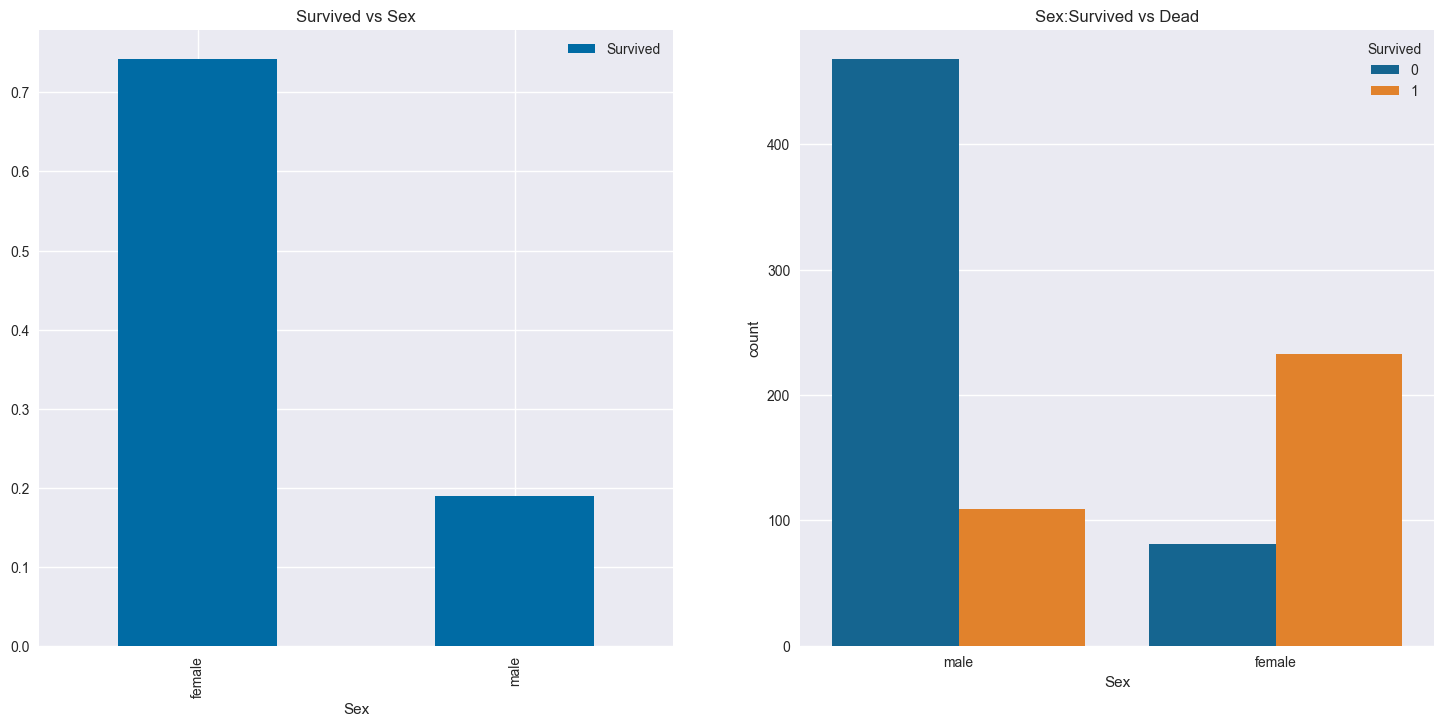

In [317]:
f, ax = plt.subplots(1, 2, figsize=(18, 8))
df[["Survived", "Sex"]].groupby("Sex").mean().plot.bar(ax=ax[0])
ax[0].set_title("Survived vs Sex")
sns.countplot(x=df["Sex"], hue=df["Survived"], ax=ax[1])
ax[1].set_title("Sex:Survived vs Dead")
plt.show()

По данным графикам можно понять что большинством выживших являются женщины (75%), в то время как мужчин выжило намного меньше (18%), это может являться одной из ключевых зависимостей в данных

    Pclass

Pclass является фичей обозначающей в каком классе проплывал пассажир, 1 - самый высокий, 3 - самый низкий класс

In [318]:
pd.crosstab(df["Pclass"], df.Survived, margins=True).style.background_gradient(
    cmap="summer_r"
)

Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


Text(0.5, 1.0, 'Количество погибших на Титанике')

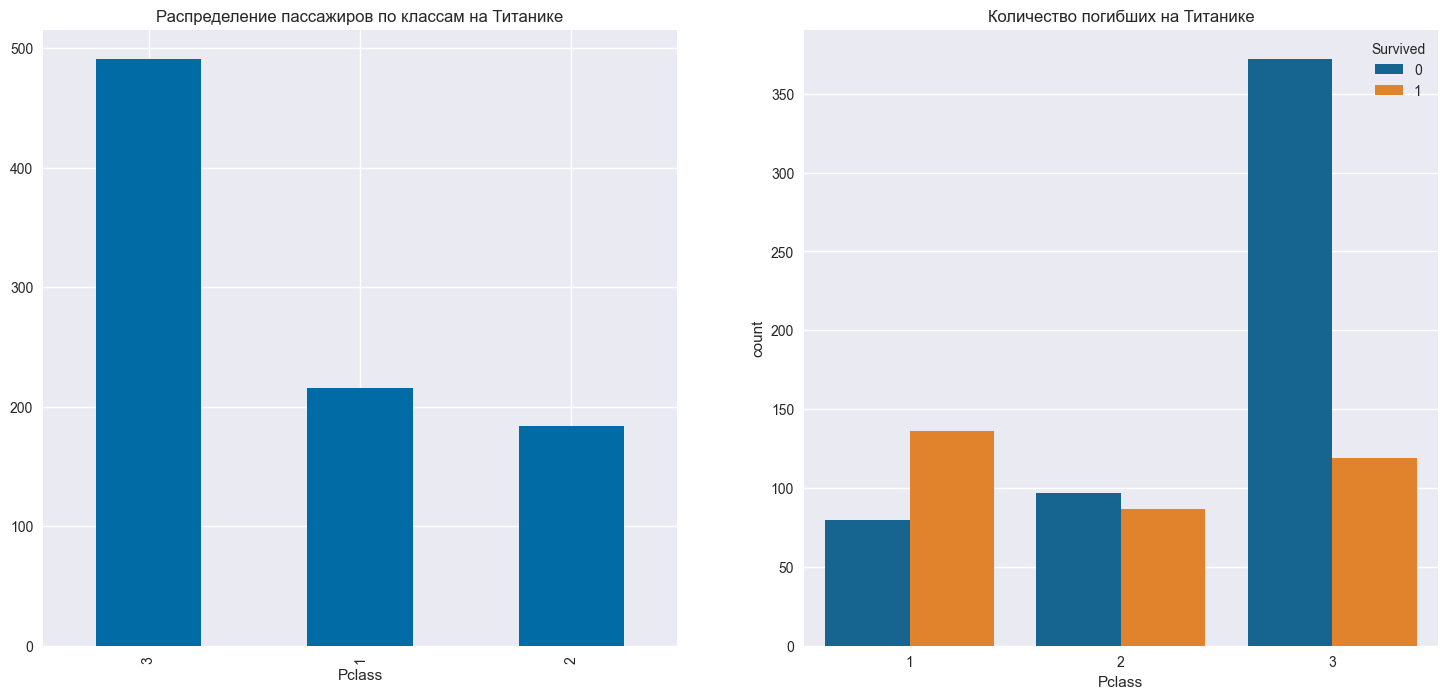

In [319]:
f, ax = plt.subplots(1, 2, figsize=(18, 8))
df["Pclass"].value_counts().plot.bar(ax=ax[0])
ax[0].set_title("Распределение пассажиров по классам на Титанике")
sns.countplot(x=df["Pclass"], hue=df["Survived"], ax=ax[1])
ax[1].set_title("Количество погибших на Титанике")

Можем заметить что большинство плыли 3ьим классом, а шанс на выживание заметно выше чем у проплывающих первым классом, посмотрим что даст совместный анализ фич 'Pclass' и 'Sex'

In [320]:
pd.crosstab(
    [df["Sex"], df["Survived"]], df["Pclass"], margins=True
).style.background_gradient(cmap="summer_r")

Заметим что женщин из первого класса выжило сравнительно больше чем мужчин из первого, а погибло во много раз меньше чем погибло мужчин из первого класса, поэтому можно сделать вывод что комбинация признаков женщина и плывет первым классом дает большие шансы на выживание, у женщин проплывающих вторым классом статистика схожа, а у жензин 3го класса шанс выжить 50/50

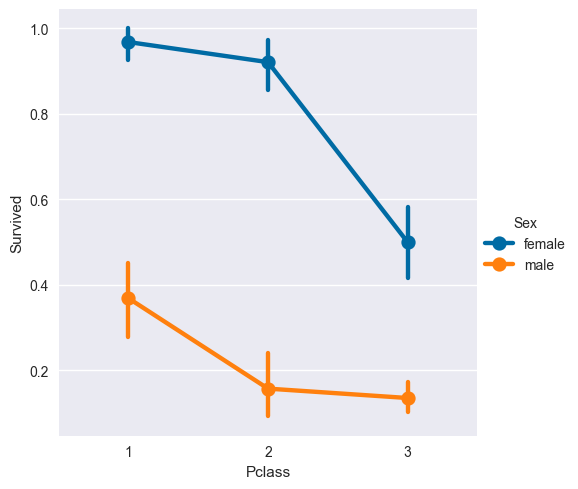

In [321]:
sns.catplot(x="Pclass", y="Survived", hue="Sex", kind="point", data=df)
plt.show()

На этом графике можно более точно увидеть что шансы на выживание у мужчин 2го,3го, классов ниже 20%

    Age

In [322]:
print("Самый старый пассажир:", df["Age"].max(), "Years")
print("Самый юнный пассажир:", df["Age"].min(), "Years")
print("Средний возраст пассажира:", df["Age"].mean(), "Years")

Самый старый пассажир: 80.0 Years
Самый юнный пассажир: 0.42 Years
Средний возраст пассажира: 29.69911764705882 Years


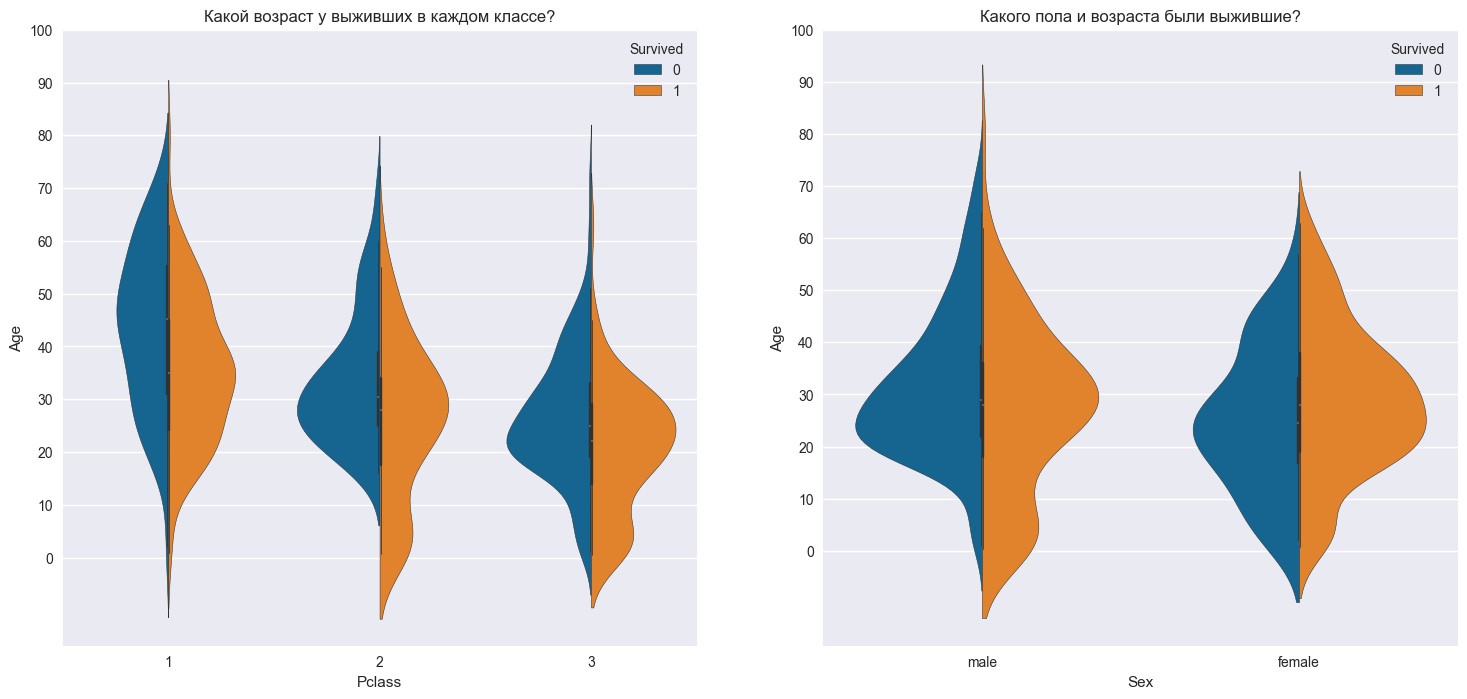

In [323]:
f, ax = plt.subplots(1, 2, figsize=(18, 8))
sns.violinplot(x="Pclass", y="Age", hue="Survived", data=df, split=True, ax=ax[0])
ax[0].set_title("Какой возраст у выживших в каждом классе?")
ax[0].set_yticks(range(0, 110, 10))
sns.violinplot(x="Sex", y="Age", hue="Survived", data=df, split=True, ax=ax[1])
ax[1].set_title("Какого пола и возраста были выжившие?")
ax[1].set_yticks(range(0, 110, 10))
plt.show()

 - Судя по данным графикам, возраст выживших в данном классе смещен больше к +- 30 годам, в то время как возраст погибших смещен по разному в зависимости от класса, для первого класса он смещен больше к 50, для 2го и 3го больше 25 годам, то есть вне зависимости от класса больше выживали люди от 40 до 20 лет.
 - Если посмотреть на второй график то можно конкретно увидеть что среди мужчин выживали чаще мужчины 30 лет, а среди женщин, женщины 25 лет
 - Так же можно отметить что количество детей увеличивается в зависимости от класса, и дети второго класса выживали намного чаще, так же чаще выживали мальчики от 0 до 10 лет, с молодыми девочками наоборот, больше погибших девочек от 0 до 10 лет

Чтобы дозаполинить возрастные фичи, мы можем посмотреть на обращения, и дозаполнить возраст средним до данному обращению (Ms,Mrs,Master)

In [324]:
df["Initial"] = 0
for i in df:
    df["Initial"] = df.Name.str.extract("([A-Za-z]+)\.")  # lets extract the Salutations

In [325]:
pd.crosstab(df.Initial, df.Sex).T.style.background_gradient(
    cmap="summer_r"
)  # Checking the Initials with the Sex

Initial,Capt,Col,Countess,Don,Dr,Jonkheer,Lady,Major,Master,Miss,Mlle,Mme,Mr,Mrs,Ms,Rev,Sir
Sex,,,,,,,,,,,,,,,,,
female,0,0,1,0,1,0,1,0,0,182,2,1,0,125,1,0,0
male,1,2,0,1,6,1,0,2,40,0,0,0,517,0,0,6,1


In [326]:
df["Initial"].replace(
    [
        "Mlle",
        "Mme",
        "Ms",
        "Dr",
        "Major",
        "Lady",
        "Countess",
        "Jonkheer",
        "Col",
        "Rev",
        "Capt",
        "Sir",
        "Don",
    ],
    [
        "Miss",
        "Miss",
        "Miss",
        "Mr",
        "Mr",
        "Mrs",
        "Mrs",
        "Other",
        "Other",
        "Other",
        "Mr",
        "Mr",
        "Mr",
    ],
    inplace=True,
)

In [327]:
df.groupby("Initial")["Age"].mean()

Initial
Master     4.574167
Miss      21.860000
Mr        32.739609
Mrs       35.981818
Other     45.888889
Name: Age, dtype: float64

In [328]:
## Если возраст не заполенен заполняем медианной по виду обращения
df.loc[(df.Age.isnull()) & (df.Initial == "Mr"), "Age"] = 33
df.loc[(df.Age.isnull()) & (df.Initial == "Mrs"), "Age"] = 36
df.loc[(df.Age.isnull()) & (df.Initial == "Master"), "Age"] = 5
df.loc[(df.Age.isnull()) & (df.Initial == "Miss"), "Age"] = 22
df.loc[(df.Age.isnull()) & (df.Initial == "Other"), "Age"] = 46

In [329]:
df.Age.isnull().any()

np.False_

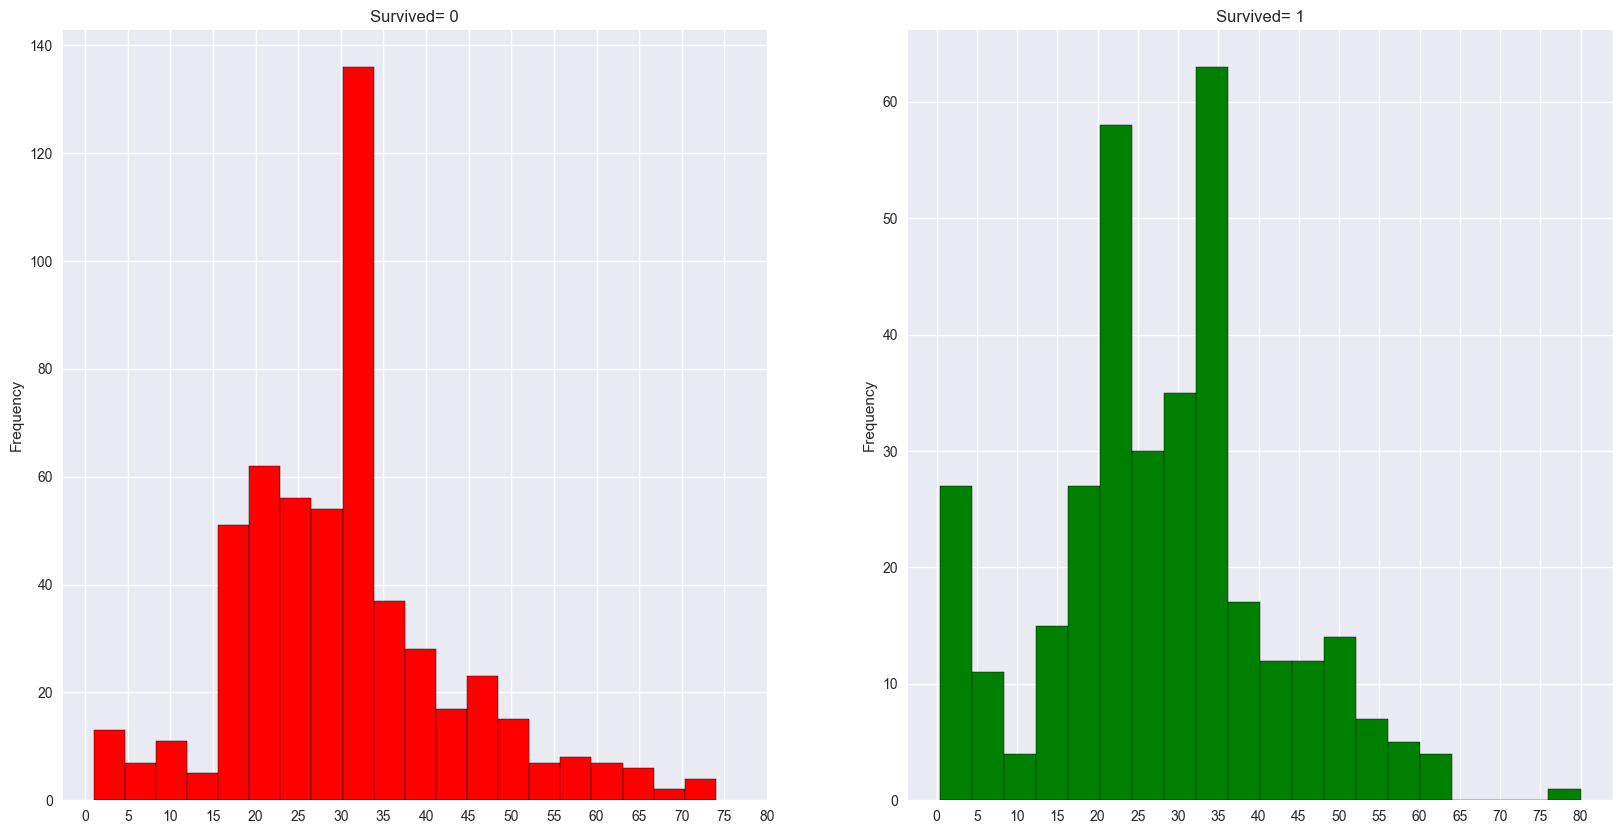

In [330]:
f, ax = plt.subplots(1, 2, figsize=(20, 10))
df[df["Survived"] == 0]["Age"].plot.hist(
    ax=ax[0], bins=20, edgecolor="black", color="red"
)
ax[0].set_title("Survived= 0")
x1 = list(range(0, 85, 5))
ax[0].set_xticks(x1)
df[df["Survived"] == 1]["Age"].plot.hist(
    ax=ax[1], color="green", bins=20, edgecolor="black"
)
ax[1].set_title("Survived= 1")
x2 = list(range(0, 85, 5))
ax[1].set_xticks(x2)
plt.show()

Посмотрев на эти графики, можем точно сказать что выживаемость у детей до 5 лет достаточно высокая, так же высокая выживаемость и сравнительно низкая смернтость у людей 20 - 25 лет (предположительно молодыне женщины)

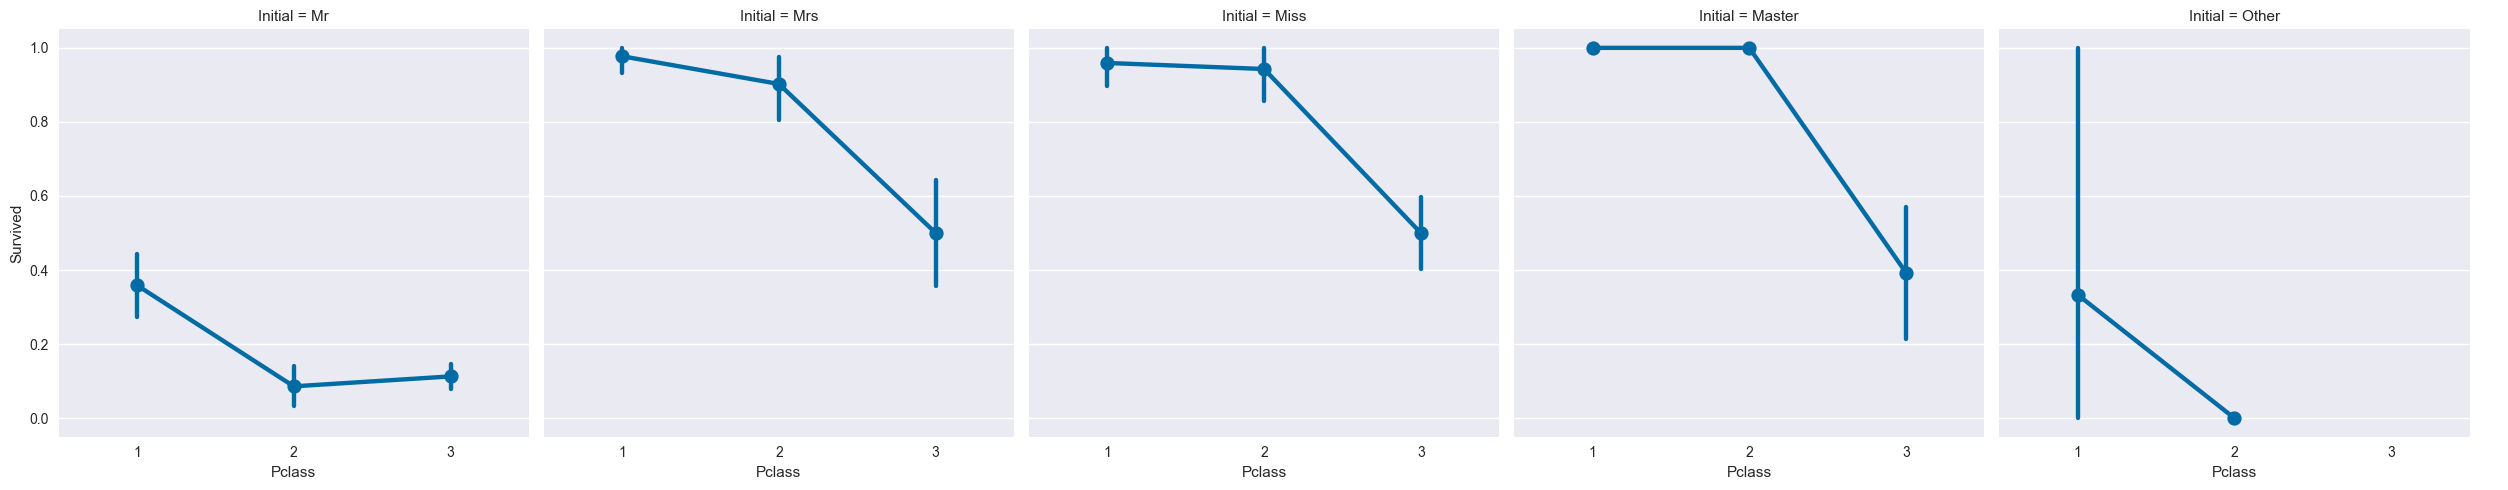

In [331]:
sns.catplot(x="Pclass", y="Survived", col="Initial", kind="point", data=df)
plt.show()

Из этих графиков видно что молодые девушки и дети имеют высокие шансы на выживание, которые уменьшаются по увеличению класса

    Embarked

In [332]:
pd.crosstab(
    [df.Embarked, df.Pclass], [df.Sex, df.Survived], margins=True
).style.background_gradient(cmap="summer_r")

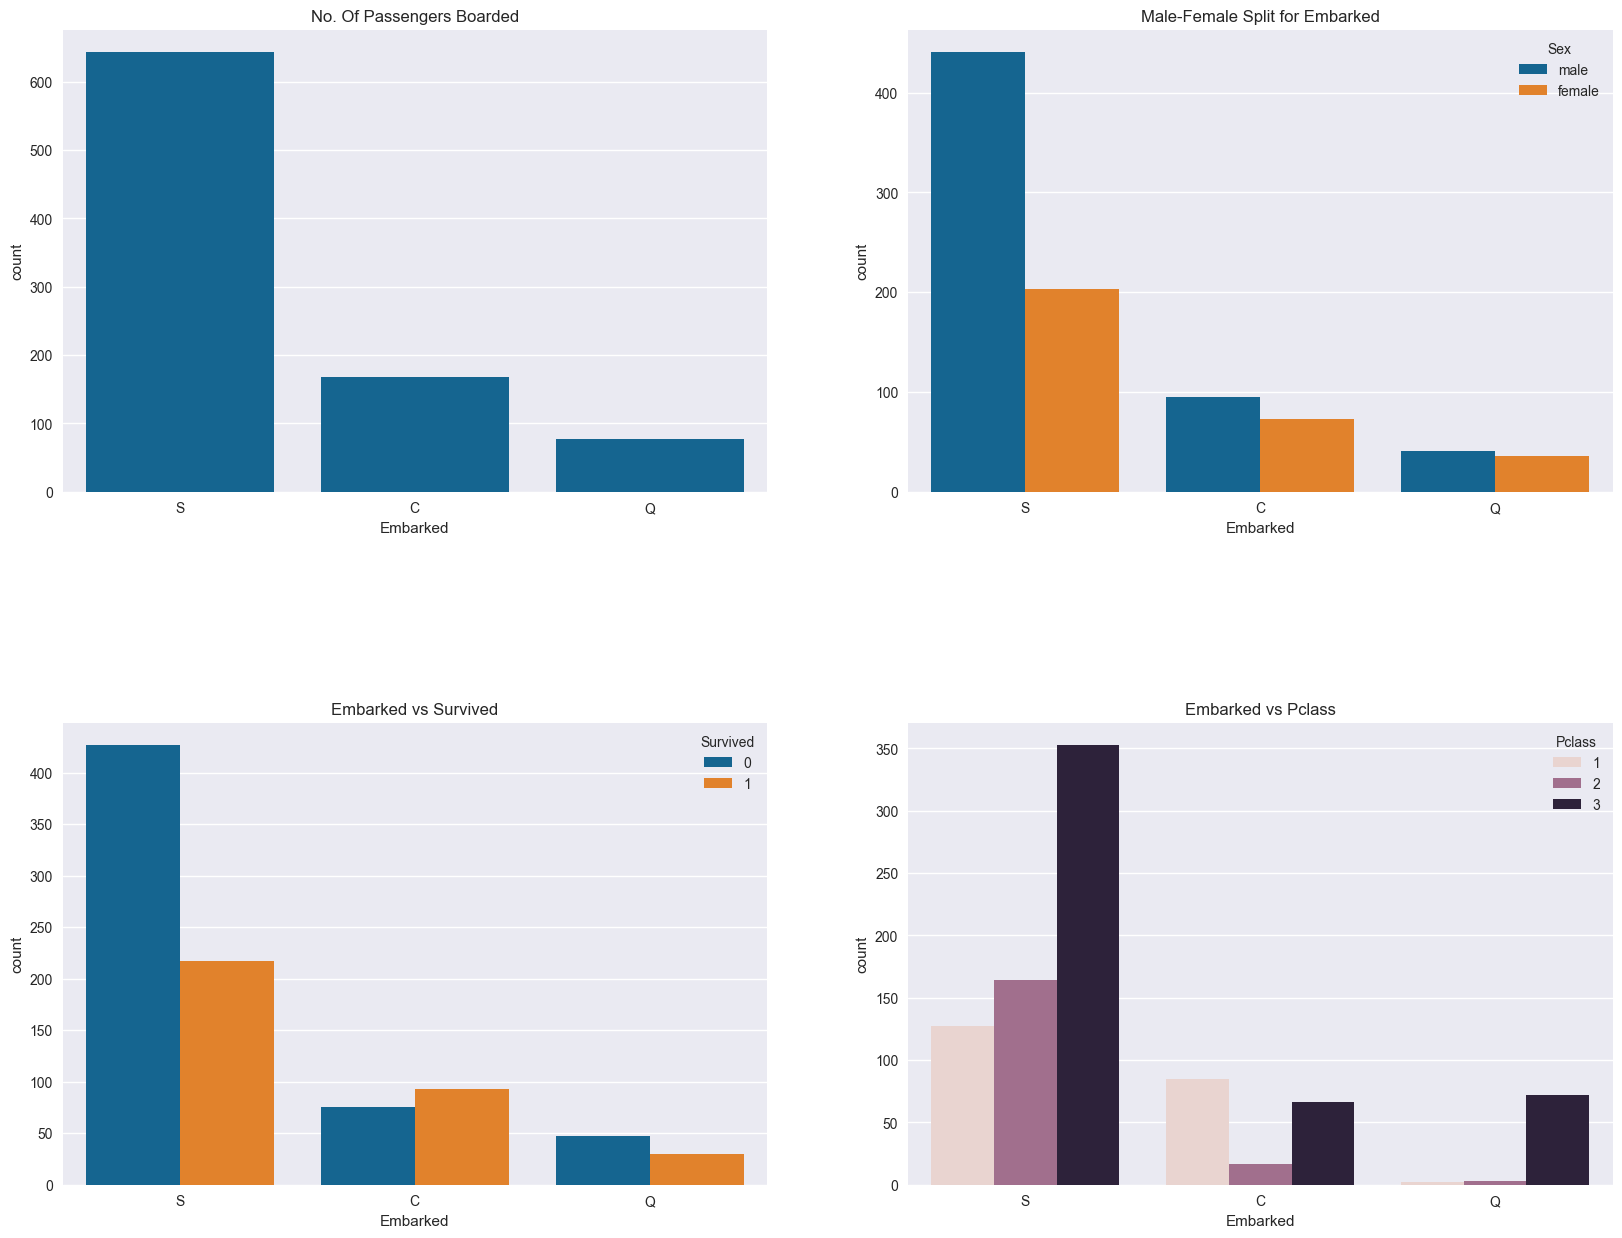

In [333]:
f, ax = plt.subplots(2, 2, figsize=(20, 15))
sns.countplot(x="Embarked", data=df, ax=ax[0, 0])
ax[0, 0].set_title("No. Of Passengers Boarded")
sns.countplot(x="Embarked", hue="Sex", data=df, ax=ax[0, 1])
ax[0, 1].set_title("Male-Female Split for Embarked")
sns.countplot(x="Embarked", hue="Survived", data=df, ax=ax[1, 0])
ax[1, 0].set_title("Embarked vs Survived")
sns.countplot(x="Embarked", hue="Pclass", data=df, ax=ax[1, 1])
ax[1, 1].set_title("Embarked vs Pclass")
plt.subplots_adjust(wspace=0.2, hspace=0.5)
plt.show()

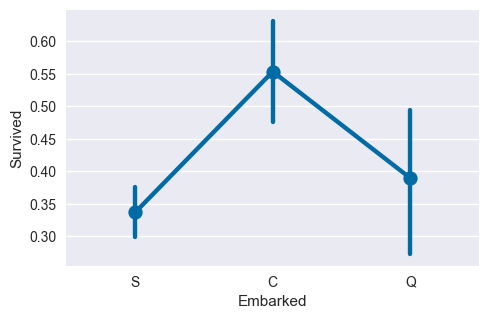

In [334]:
sns.catplot(x="Embarked", y="Survived", kind="point", data=df)
fig = plt.gcf()
fig.set_size_inches(5, 3)
plt.show()

У севших в порту C шансов на выживание больше

Так как больше всего народу село в порту S, заменим пропуски в данной фиче на S

In [335]:
df["Embarked"].fillna("S", inplace=True)

    SibSip

In [336]:
pd.crosstab([df.SibSp], df.Survived).style.background_gradient(cmap="summer_r")

Survived,0,1
SibSp,,
0,398,210
1,97,112
2,15,13
3,12,4
4,15,3
5,5,0
8,7,0


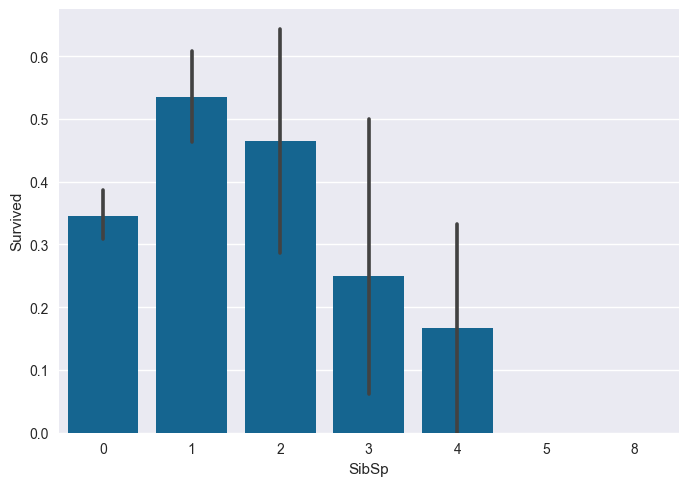

In [337]:
sns.barplot(x="SibSp", y="Survived", data=df)
plt.show()

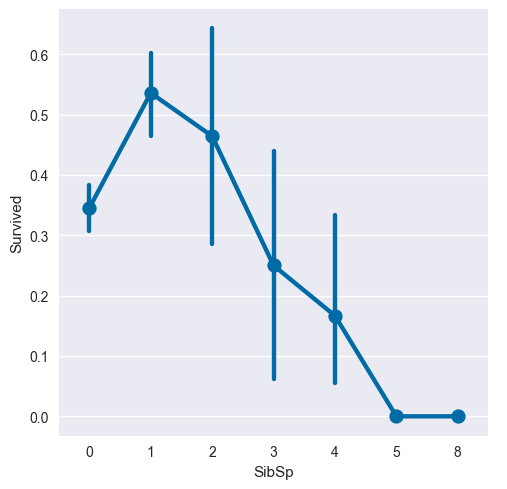

In [338]:
sns.catplot(x="SibSp", y="Survived", data=df, kind="point")
plt.show()

In [339]:
pd.crosstab(df.SibSp, df.Pclass).style.background_gradient(cmap="summer_r")

Pclass,1,2,3
SibSp,,,
0,137,120,351
1,71,55,83
2,5,8,15
3,3,1,12
4,0,0,18
5,0,0,5
8,0,0,7


Возможно чем больше у тебя проплывает родствеников на корабле чем меньше у тебя шанс на выживание, так как люди с большим кол-вом родственников обычно плывут третьим классом

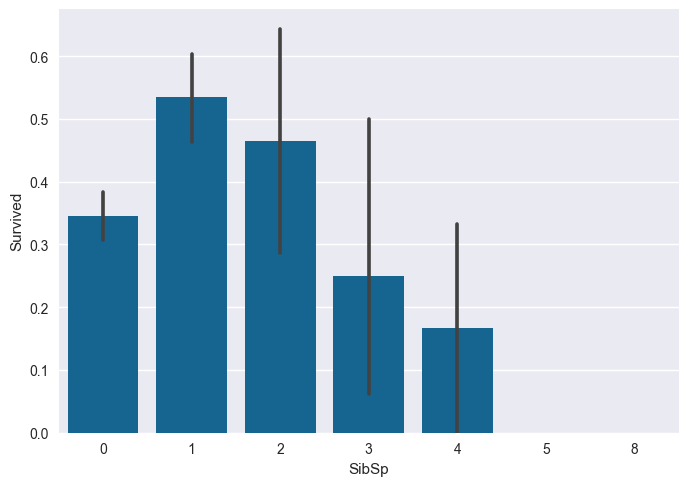

In [340]:
sns.barplot(x=df["SibSp"], y=df["Survived"], data=df)
plt.show()

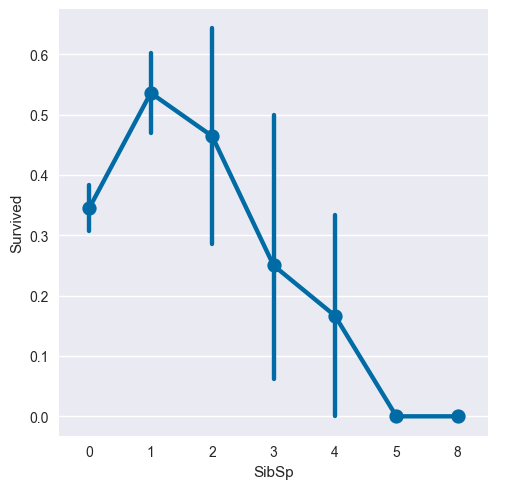

In [341]:
sns.catplot(x=df["SibSp"], y=df["Survived"], kind="point", data=df)
plt.show()

В целом если ты едешь не один то тогда шасы выжить у тебя больше, но количество родственников не должно быть чрезмерным

    Parch

In [342]:
pd.crosstab(df["Parch"], df["Pclass"]).style.background_gradient(cmap="summer_r")

Pclass,1,2,3
Parch,,,
0,163,134,381
1,31,32,55
2,21,16,43
3,0,2,3
4,1,0,3
5,0,0,5
6,0,0,1


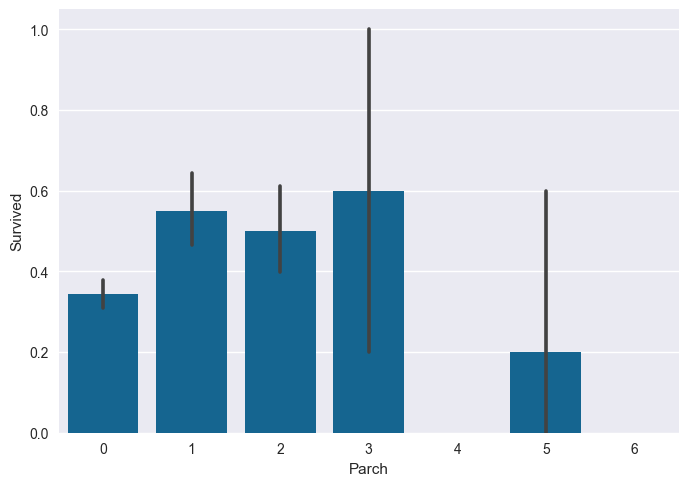

In [343]:
sns.barplot(x=df["Parch"], y=df["Survived"], data=df)
plt.show()

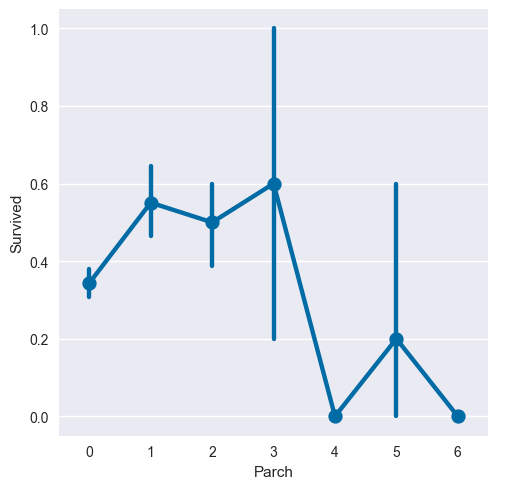

In [344]:
sns.catplot(x=df["Parch"], y=df["Survived"], kind="point", data=df)
plt.show()

Как мы видим наибольший шанс выживания у людей плывущих с одним/двумя ребенком/родителем, что логично ведь в случае ребенком родитель постарается всячески его спасти, но тут так же прослеживается зависимость от класса в котром плывет пассажир

## Резюме по фичам
- Пол - Для женщины шанс выжить намного выше чем для мужчины
- Pclass - Пассажиры первого класса имеют очень высокие шансы на выживание, в особенности женщины
- Age - Женщины возраста от 20 до 35 много выживали, но и умирало их так же очень много, так же много выживших среди пасажиров 0 - 10 лет, старики почти не выживали (лишь один спасенный 80 лет), чем выше класс тем большее смешение возраста выживших в сторону 20 лет
- Большие семьи почти не выживали, наибольшие шансы имели семьи с 1-2 родствениками
- У севших в порту C шансы на выживание больше

Хочется попробовать использовать имя чтобы разделить всех пасажиров по семьям, чтобы проверить гипотезу - представители одной семьи либо умирают либо выживают все вместе. Как мы видим фамилия у нас отделена от имени запятой, поэтому ее не сложно выделить

### Корелляция между признаками

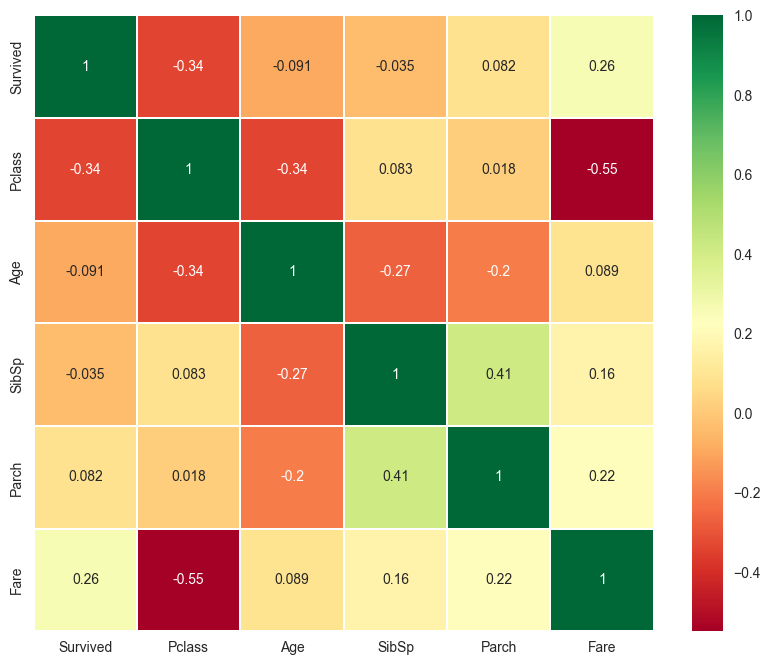

In [345]:
sns.heatmap(
    df.drop(columns=["PassengerId"]).corr(numeric_only="True"),
    annot=True,
    cmap="RdYlGn",
    linewidths=0.2,
)  # df.corr()-->correlation matrix
fig = plt.gcf()
fig.set_size_inches(10, 8)
plt.show()

Мультикорлениарности между фичами не имется, самая высокая кореляция с целевой фичей у класса, чем он ниже тем выше выживаемость, так же относительно высокая у цены за билет, это связанно с тем что билеты за лучший класс дороже

## Feature engeneering

Предлагается сделать несколько фичей:
- Возрастная группа, разделить всех пассажиров на 4 возрастные группы, дети,молодые,взрослые и старики в соответсвии с распределением выживаемости по возрастам
- Хочется добавить фичу богатая женщина, если она не будет иметь мультикорелинарности с возрастом
- Так же добавим фичу "Размер семьи", она будет считаться из суммы Siblings + Parch
- Поделим фичу Fare, на 4 бина и посмотрим шансы на выживания в каждом из них, так как фича Fare имеет кореляцию c Survived

 - Новая фича: разделить семьи по группам и мб попробовать таргет энкодинг

In [346]:
df["Age_band"] = 0
df.loc[df["Age"] <= 16, "Age_band"] = 0
df.loc[(df["Age"] > 16) & (df["Age"] <= 35), "Age_band"] = 1
df.loc[(df["Age"] > 35) & (df["Age"] <= 48), "Age_band"] = 2
df.loc[(df["Age"] > 48) & (df["Age"] <= 64), "Age_band"] = 3
df.loc[df["Age"] > 64, "Age_band"] = 4

In [347]:
df.groupby(["Age_band"])["Survived"].mean().to_frame().style.background_gradient(
    cmap="summer_r"
)

,Survived
Age_band,
0,0.548077
1,0.339964
2,0.428571
3,0.434783
4,0.090909


<Axes: xlabel='Sex', ylabel='Age_band'>

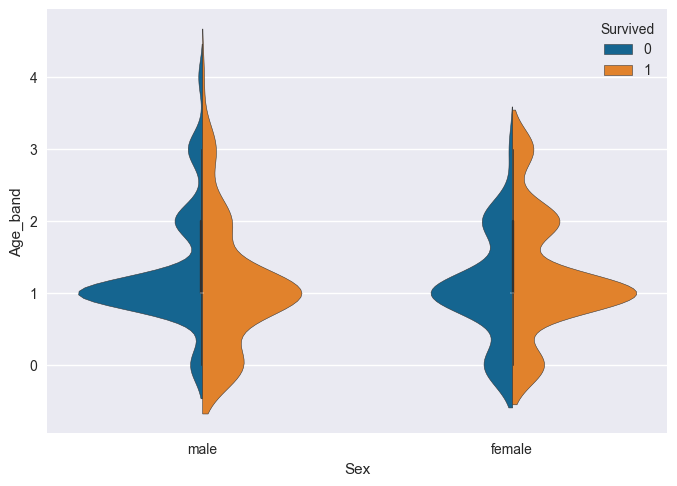

In [348]:
sns.violinplot(x="Sex", y="Age_band", hue="Survived", data=df, split=True)

In [349]:
df["Rich_Woman"] = ((df["Sex"] == "female") & (df["Pclass"] == 1)).astype(int)

In [350]:
pd.crosstab([df["Rich_Woman"]], df["Survived"], margins=True).style.background_gradient(
    cmap="summer_r"
)

Survived,0,1,All
Rich_Woman,,,
0,546,251,797
1,3,91,94
All,549,342,891


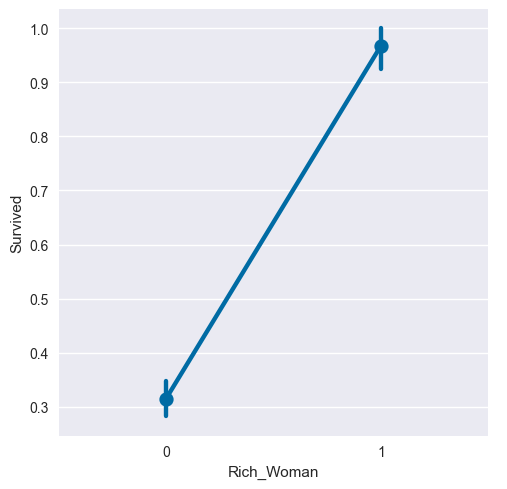

In [351]:
sns.catplot(x="Rich_Woman", y="Survived", data=df, kind="point")
plt.show()

In [352]:
df["Alone"] = 0
df["Family_size"] = df["SibSp"] + df["Parch"]
df.loc[df["Family_size"] == 0, "Alone"] = 1

In [353]:
pd.crosstab([df["Sex"]], df["Alone"], margins=True).style.background_gradient(
    cmap="summer_r"
)

Alone,0,1,All
Sex,,,
female,188,126,314
male,166,411,577
All,354,537,891


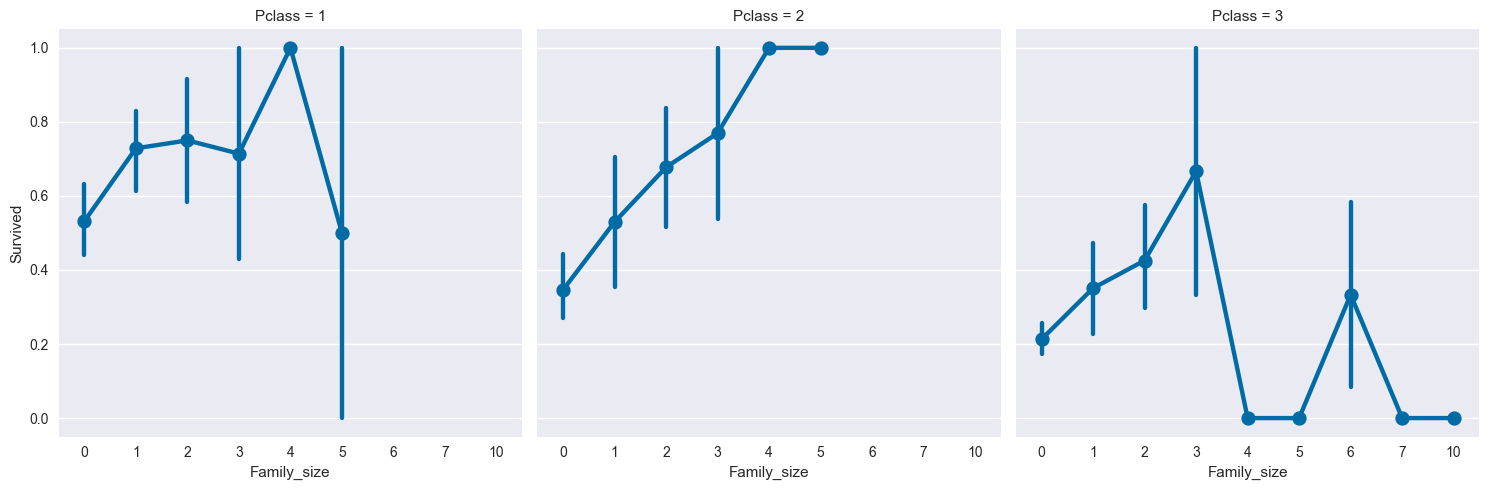

In [354]:
sns.catplot(x="Family_size", y="Survived", data=df, kind="point", col="Pclass")
plt.show()

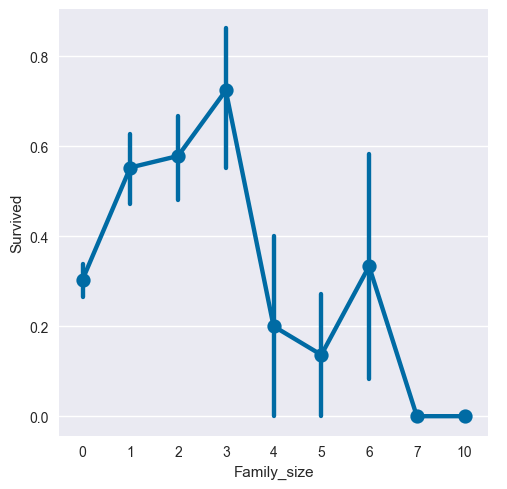

In [355]:
sns.catplot(x="Family_size", y="Survived", data=df, kind="point")
plt.show()

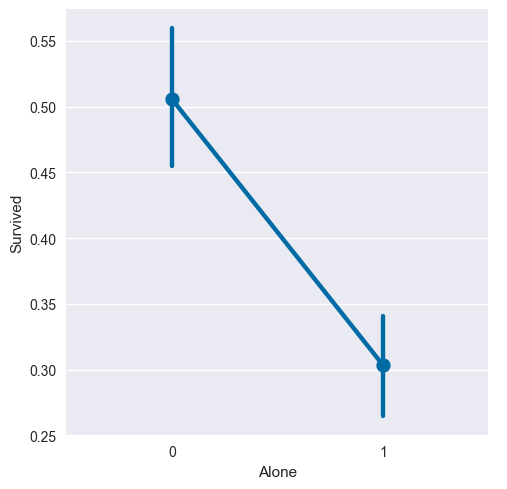

In [356]:
sns.catplot(x="Alone", y="Survived", data=df, kind="point")
plt.show()

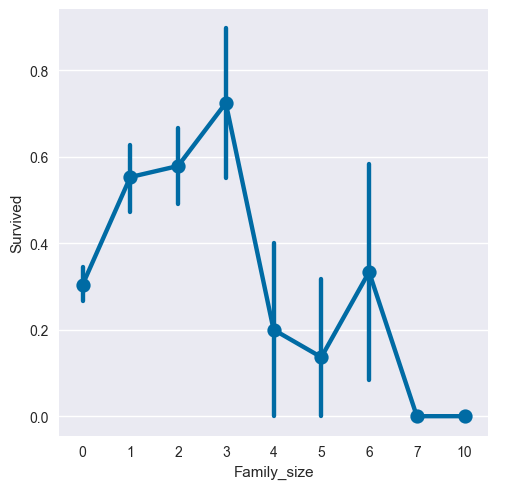

In [357]:
sns.catplot(x="Family_size", y="Survived", data=df, kind="point")
plt.show()

<Axes: xlabel='Rich_Woman', ylabel='Family_size'>

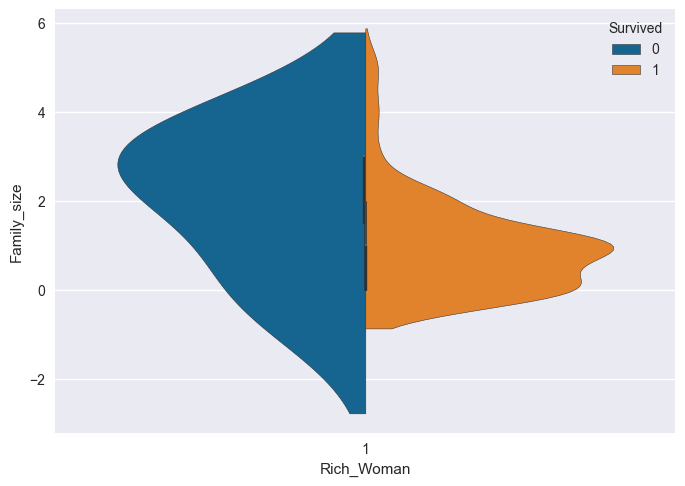

In [358]:
sns.violinplot(
    x="Rich_Woman",
    y="Family_size",
    hue="Survived",
    data=df[df["Rich_Woman"] == 1],
    split=True,
)

### FamilyID and Family_Survival_Rate

In [359]:
df["FamilyID"] = df["Name"].str.split(",").str[0] + "_" + df["Ticket"]

Посчитаем кол-во семей в которых либо все умерли либо все выжили

In [360]:
family_stats = df.groupby("FamilyID")["Survived"].agg(
    family_size="count", survivors="sum"
)
family_stats["status"] = np.select(
    [
        family_stats["survivors"] == 0,
        family_stats["survivors"] == family_stats["family_size"],
    ],
    ["all_died", "all_survived"],
    default="mixed",
)

family_stats["status"].value_counts()

status
all_died        448
all_survived    251
mixed            40
Name: count, dtype: int64

In [361]:
mapping = df.set_index("FamilyID")["Pclass"].to_dict()

In [362]:
family_stats["Pclass"] = family_stats.index.map(mapping)

In [363]:
ct = (
    pd.crosstab([family_stats["status"]], family_stats["Pclass"], normalize="columns")
    * 100
)
ct.style.background_gradient(cmap="summer_r").format("{:.1f}%")

Pclass,1,2,3
status,,,
all_died,34.3%,52.6%,75.1%
all_survived,56.7%,38.8%,22.2%
mixed,9.0%,8.6%,2.7%


In [364]:
ct = pd.crosstab(df["Survived"], df["Pclass"], margins=True, normalize="columns") * 100
ct.style.background_gradient(cmap="summer_r").format("{:.1f}%")

Pclass,1,2,3,All
Survived,,,,
0,37.0%,52.7%,75.8%,61.6%
1,63.0%,47.3%,24.2%,38.4%


<Axes: xlabel='Pclass', ylabel='count'>

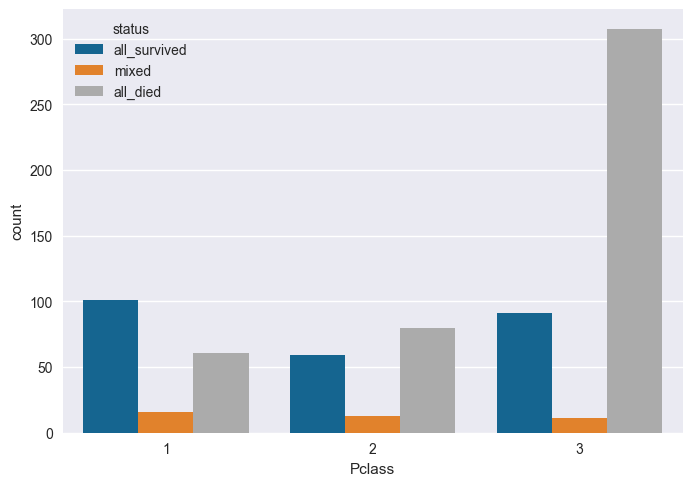

In [365]:
sns.countplot(x="Pclass", hue="status", data=family_stats)

Хочется понять насколько согласуются проценты выживания в семьях с процентом выживания в классе, и стоит ли их занижать, так как в следствии этого фичи могут стать мультиколенеарными

Видим что гипотеза работоспособна так как число семей со смешанным количеством выживших или погибших очень мало 


## Формула для расчета фичи:
- 
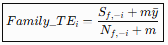
- 
где:
- Sf — общее количество выживших в семье;
- yi — Survived конкретного пассажира;
- Nf — количество членов семьи;
- m — сглаживание.
- y c крышкой - общий шанс выживани на корабле 0.38, по сути это для челов без семей чтобы не занулять фичу а говорить, что если чел без семьи шанс его выживнаию равен среднему шансу выживания
 
То есть при уменьшении класса мы все больше ссылаемся на семейную информацию
   
Надо расчитать для каждого выжившего:
- Коэффициент выживаемости членов его семьи без учета информации о нем самом

m — это фактически сила априорного знания. Его размерность соответствует количеству условных наблюдений.
Например:
\[
m=5
\]
означает примерно:
«Перед тем как доверять статистике семьи, я условно добавляю 5 наблюдений с вероятностью выживания y». Это по сути будет как гиперпараметр 

In [366]:
m = 5  # Глобальное сглаживание
y_ = 0.38  # Глобальный шанс выживания

In [367]:
df["Amount_of_surviors_in_family"] = df["FamilyID"].map(
    df.groupby("FamilyID")["Survived"].sum()
)

In [368]:
df["Family_TE"] = (
    df["FamilyID"].map(df.groupby("FamilyID")["Survived"].sum())
    - df["Survived"]
    + m * y_
) / (df["Family_size"] + m)

In [369]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Initial,Age_band,Rich_Woman,Alone,Family_size,FamilyID,Amount_of_surviors_in_family,Family_TE
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr,1,0,0,1,Braund_A/5 21171,0,0.316667
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,2,1,0,1,Cumings_PC 17599,1,0.316667
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss,1,0,1,0,Heikkinen_STON/O2. 3101282,1,0.380000
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs,1,1,0,1,Futrelle_113803,1,0.316667
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr,1,0,1,0,Allen_373450,0,0.380000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Other,1,0,1,0,Montvila_211536,0,0.380000
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Miss,1,1,1,0,Graham_112053,1,0.380000
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,22.0,1,2,W./C. 6607,23.4500,NaN,S,Miss,1,0,0,3,Johnston_W./C. 6607,0,0.237500
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Mr,1,0,1,0,Behr_111369,1,0.380000


Будем расчитывать данную фичу в процессе крос валидации, отдельно на каждом тренировочном фолде, чтобы избежать лика, поэтому мы ее дропнем, после проверки на мулькореленарность

## Fare_Range

In [370]:
df["Fare_Range"] = pd.qcut(df["Fare"], 4)
df.groupby(["Fare_Range"])["Survived"].mean().to_frame().style.background_gradient(
    cmap="summer_r"
)

,Survived
Fare_Range,
"(-0.001, 7.91]",0.197309
"(7.91, 14.454]",0.303571
"(14.454, 31.0]",0.454955
"(31.0, 512.329]",0.581081


In [371]:
df["Fare_cat"] = 0
df.loc[df["Fare"] <= 7.91, "Fare_cat"] = 0
df.loc[(df["Fare"] > 7.91) & (df["Fare"] <= 14.454), "Fare_cat"] = 1
df.loc[(df["Fare"] > 14.454) & (df["Fare"] <= 31), "Fare_cat"] = 2
df.loc[(df["Fare"] > 31) & (df["Fare"] <= 513), "Fare_cat"] = 3

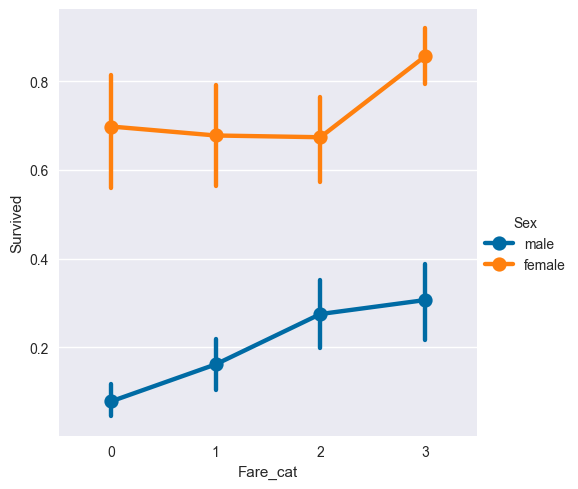

In [372]:
sns.catplot(x="Fare_cat", y="Survived", data=df, hue="Sex", kind="point")
plt.show()

In [ ]:
df["Sex"].replace(["male", "female"], [0, 1], inplace=True)
df["Embarked"].replace(["S", "C", "Q"], [0, 1, 2], inplace=True)
df["Initial"].replace(
    ["Mr", "Mrs", "Miss", "Master", "Other"], [0, 1, 2, 3, 4], inplace=True
)

# Combo-features
df["Age*Class"] = df["Age"] * df["Pclass"]

In [374]:
df.drop(
    [
        "Age",
        "Fare",
        "Cabin",
        "Fare_Range",
        "Name",
        "PassengerId",
        "Amount_of_surviors_in_family",
        "Ticket",
    ],
    axis=1,
    inplace=True,
)  # Amount_of_surviors_in_family ликовая фича, имеет инфу о выживании самого пассажира

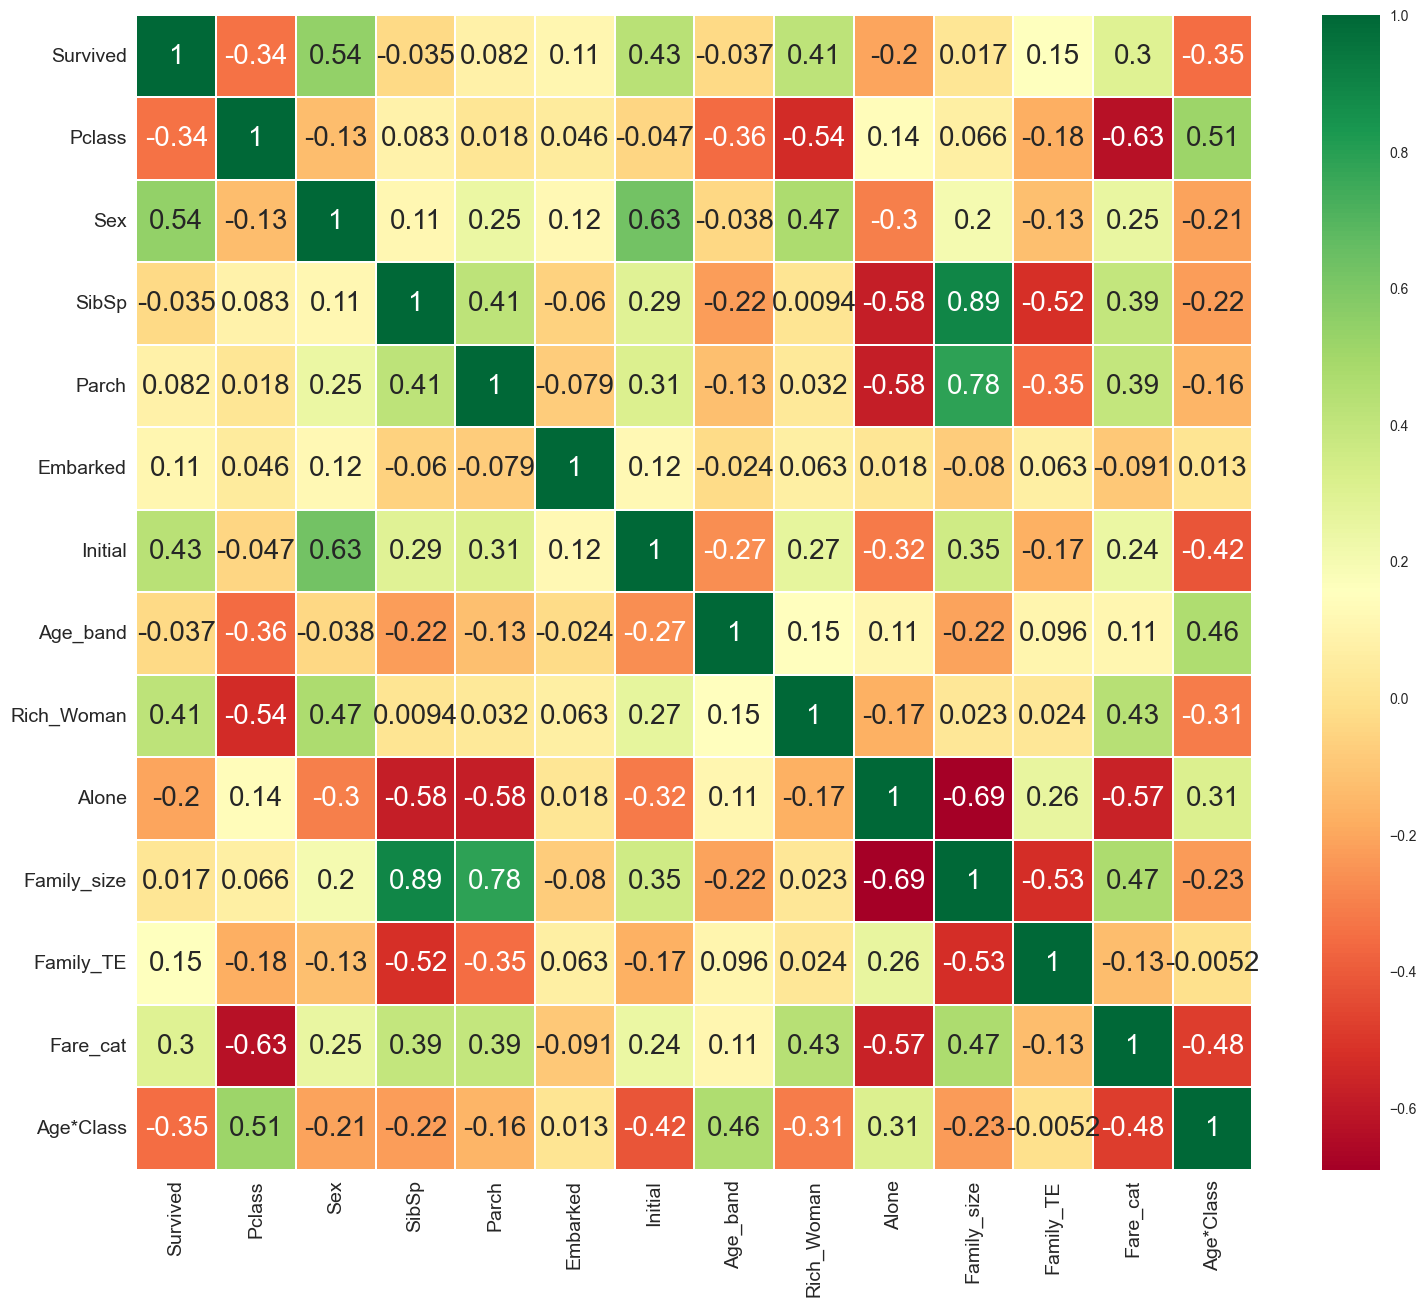

In [375]:
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="RdYlGn",
    linewidths=0.2,
    annot_kws={"size": 20},
)
fig = plt.gcf()
fig.set_size_inches(18, 15)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [376]:
df.drop(["SibSp", "Parch", "Family_TE"], axis=1, inplace=True)

Удалим эти фичи из-за мультикорелениарности

<Axes: >

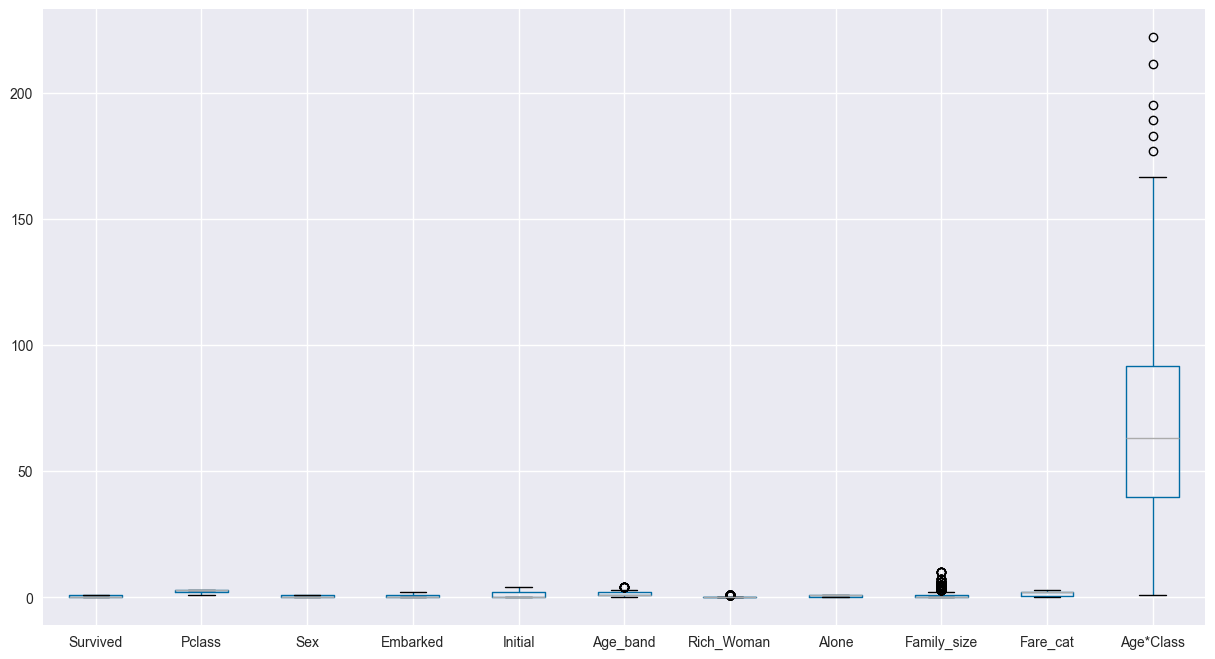

In [377]:
df.boxplot(figsize=(15, 8))

In [378]:
df.to_csv("train_data.csv", index=False)

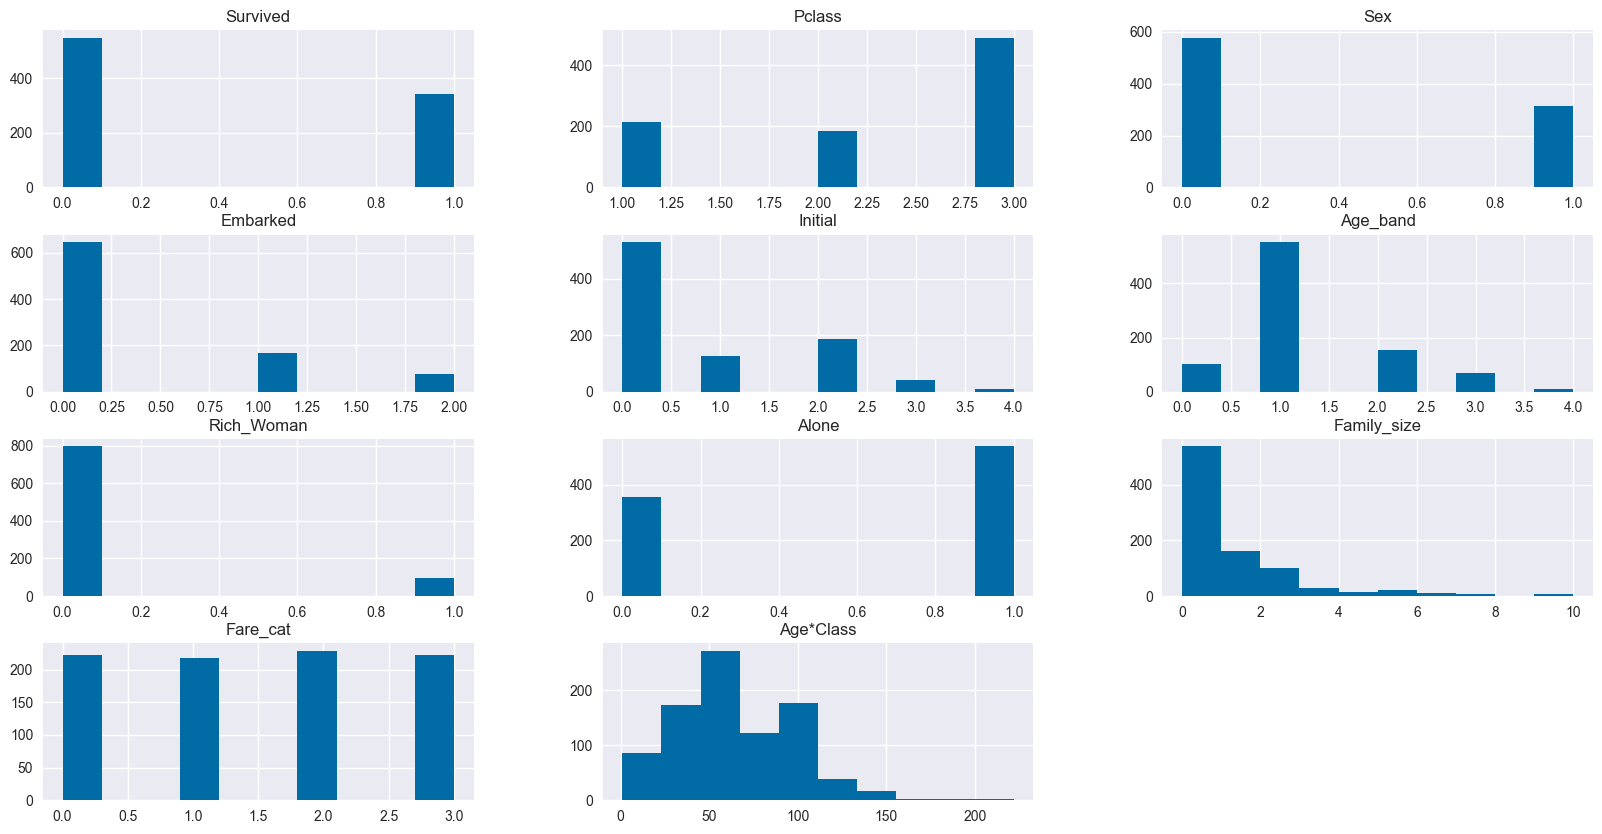

In [379]:
df.hist(figsize=(20, 10))
plt.show()